In [1]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd
import geopandas as geopd


# =========================
# Geometry / GIS
# =========================
import shapely.wkt as wkt

from shapely.geometry import LineString, Polygon, Point

import mapclassify


# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_pickle('../../../../Data/e2018.pkl')
df.rename(columns={'BADGE':'badge'},inplace=True)
df.rename(columns={'DATE_RD':'date'},inplace=True)
df1 = pd.read_csv("../../../../Data/household_data/badge_location.csv")
df = pd.merge(df,df1[['badge','tractID','blockID']],on='badge',how='left')
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df[df["date"].dt.month == 4]
df = df.dropna(subset=["blockID", "tractID"]).reset_index(drop=True)
df["blockID"] = df["blockID"].astype(int)
df["tractID"] = df["tractID"].astype(int)
df["blockID"] = df["blockID"].astype(str)
df['blockgroupID'] = df['blockID'].str[:5]
df["tractID"] = df["tractID"].astype(str)
df.index = range(df.shape[0])
df.head(2)

,badge,date,INT_VALUE_0000,INT_VALUE_0030,INT_VALUE_0100,INT_VALUE_0130,INT_VALUE_0200,INT_VALUE_0230,INT_VALUE_0300,INT_VALUE_0330,INT_VALUE_0400,INT_VALUE_0430,INT_VALUE_0500,INT_VALUE_0530,INT_VALUE_0600,INT_VALUE_0630,INT_VALUE_0700,INT_VALUE_0730,INT_VALUE_0800,INT_VALUE_0830,INT_VALUE_0900,INT_VALUE_0930,INT_VALUE_1000,INT_VALUE_1030,INT_VALUE_1100,INT_VALUE_1130,INT_VALUE_1200,INT_VALUE_1230,INT_VALUE_1300,INT_VALUE_1330,INT_VALUE_1400,INT_VALUE_1430,INT_VALUE_1500,INT_VALUE_1530,INT_VALUE_1600,INT_VALUE_1630,INT_VALUE_1700,INT_VALUE_1730,INT_VALUE_1800,INT_VALUE_1830,INT_VALUE_1900,INT_VALUE_1930,INT_VALUE_2000,INT_VALUE_2030,INT_VALUE_2100,INT_VALUE_2130,INT_VALUE_2200,INT_VALUE_2230,INT_VALUE_2300,INT_VALUE_2330,address,district,tractID,blockID,blockgroupID
0,E162956,2018-04-01,1.62,1.45,1.44,1.59,1.18,0.75,0.95,0.80,0.79,0.75,0.76,0.77,0.89,0.78,1.16,2.04,3.90,2.18,0.80,0.34,0.31,0.13,0.14,0.26,0.22,0.38,0.14,0.29,0.11,0.14,0.16,0.15,0.26,0.14,0.17,0.17,0.19,0.28,0.24,0.17,0.17,0.14,0.22,0.30,0.14,0.13,0.15,0.31,46.0,POINT (-84.30334 30.388433),1801,18011011,18011
1,E162956,2018-04-02,0.17,0.15,0.16,0.27,0.13,0.16,0.11,0.13,0.29,0.12,0.14,0.10,0.31,0.09,0.18,0.55,0.88,0.60,0.54,0.52,0.88,0.21,0.61,1.87,2.68,2.51,2.52,2.25,0.17,0.42,0.18,0.18,0.31,0.22,0.33,0.27,0.66,0.11,0.42,0.49,1.00,0.92,0.26,0.34,0.64,0.21,0.38,0.16,46.0,POINT (-84.30334 30.388433),1801,18011011,18011


In [6]:
boundary_block = pd.read_csv('../../../../Data/boundary_data/tal_block_boundary.csv')
boundary_block["geometry"] = geopd.GeoSeries.from_wkt(boundary_block["geometry"])
boundary_block = geopd.GeoDataFrame(boundary_block, crs="EPSG:4326")
boundary_block["centroid"] = geopd.GeoSeries.from_wkt(boundary_block["centroid"])
boundary_block.head(2)

,tractID,blockID,geoID,geometry,centroid
0,2505,25054048,120730025054048,"POLYGON ((-84.21645 30.45289, -84.21638 30.452...",POINT (-84.21505 30.45322)
1,1801,18012017,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094)


In [7]:
boundary_block_group = boundary_block.copy()
boundary_block_group["blockgroupID"] = boundary_block_group["blockID"].astype(str).str[:5]
boundary_block_group = boundary_block_group[['tractID','blockID','blockgroupID','geoID','geometry','centroid']]

In [8]:
id_cols = ["badge", "date", "address", "district", "tractID", "blockID",'blockgroupID']

value_cols = [c for c in df.columns if c.startswith("INT_VALUE_")]
# 若 df 构造时保证列顺序就是 0000→2330，可不用再 sort；否则会乱序时按时间后缀排序更安全：
value_cols = sorted(value_cols)

assert len(value_cols) == 48, len(value_cols)

# 形状 (行数, 6 个四小时段, 每段 8 个半小时点) → 在最后一维求和 → (行数, 6)
arr_4h = df[value_cols].to_numpy(dtype="float64").reshape(len(df), 6, 8).sum(axis=2)

new_cols = [
    "INT_4h_1",  # 00:00–03:30
    "INT_4h_2",
    "INT_4h_3",
    "INT_4h_4",
    "INT_4h_5",
    "INT_4h_6",
]

df1 = pd.concat([df[id_cols].reset_index(drop=True), pd.DataFrame(arr_4h, columns=new_cols)], axis=1)

In [9]:
import pandas as pd
import numpy as np

value_cols = [f"INT_4h_{i}" for i in range(1, 7)]
meta_cols = ["address", "district", "tractID", "blockID",'blockgroupID']

base = df1.copy()
base["day"] = pd.to_datetime(base["date"], errors="coerce").dt.normalize()

# （可选）同一天同一 badge 若有多条，先按业务规则聚合：这里用最常见的“求和”，你可改成 mean/first 等。
base = (
    base.groupby(["badge", "day"], as_index=False)[value_cols + meta_cols]
    .agg({**{c: "sum" for c in value_cols}, **{c: "first" for c in meta_cols}})
)

badges = np.sort(base["badge"].unique())

# TODO: 用你的 30 天替换这里（要包含你希望对齐的那 30 个 calendar day）
day_range = pd.date_range("2018-04-01", periods=30, freq="D").normalize()

idx = pd.MultiIndex.from_product([badges, day_range], names=["badge", "day"])

wide06 = (
    base.set_index(["badge", "day"])[value_cols]
    .reindex(idx)
    .fillna(0)
)

# （可选自检）理论上每个 badge 正好 30 行 × 6 列 → 180
assert wide06.groupby(level=0).size().eq(30).all(), "badge-day 不完整，请检查 day_range"

# （badge，day）已按字典序：先 badge，再日期；对每个 badge，30 天的 6 列按行展开成 180
n_badge = badges.size
n_day = day_range.size
arr180 = wide06.to_numpy(dtype=float).reshape(n_badge, n_day * 6)

# 列名也可用 f"{day}_{k}"；这里给一个简单的 t000 ~ t179
col180 = [f"t{i:03d}" for i in range(180)]

meta = (
    base.sort_values(["badge", "day"])
        .drop_duplicates("badge")
        .set_index("badge")[meta_cols]
    .reindex(badges)  # 与 badges 对齐
)

df2 = pd.concat(
    [
        meta,
        pd.DataFrame(arr180, index=badges, columns=col180),
    ],
    axis=1,
).reset_index(names="badge")   # pandas>=2；若报错可改成 reset_index().rename(...)

In [10]:
import re
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols)  # t000,t001,...,t179
X = df2[feat_cols].to_numpy(dtype=np.float64)  # 形状 (N, 180)
assert X.shape[1] == 180
assert X.shape[0] == len(df2)

In [11]:
z = np.asarray(X, dtype=float).ravel()
z = z[np.isfinite(z)]
thresh_high = np.quantile(z, 0.90)    
print(f"90% 阈值: {thresh_high:.2f}")

90% 阈值: 9.98


In [12]:
thresh_low = np.quantile(z, 0.05)    
print(f"5% 阈值: {thresh_low:.2f}")    

5% 阈值: 0.12


In [13]:
import re
import numpy as np
# 选出 180 个特征列（按你实际的列命名改这里的规则）
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols, key=lambda x: int(str(x)[1:]))
assert len(feat_cols) == 180, len(feat_cols)
X = df2[feat_cols].to_numpy(dtype=float)
# 每个 badge（每一行）：180 个数里有多少 > thresh
prop = np.mean(X > thresh_high, axis=1)
df2["prop_high"] = prop

In [14]:
import re
import numpy as np
# 选出 180 个特征列（按你实际的列命名改这里的规则）
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols, key=lambda x: int(str(x)[1:]))
assert len(feat_cols) == 180, len(feat_cols)
X = df2[feat_cols].to_numpy(dtype=float)
# 每个 badge（每一行）：180 个数里有多少 > thresh
prop = np.mean(X <= thresh_low, axis=1)
df2["prop_low"] = prop

In [15]:
df2 = df2[df2['prop_low'] <= 0.7]
df3 = df2[['badge','blockID','prop_high','prop_low']]
df3 = (
    df3.groupby("blockID", as_index=False)[["prop_high", "prop_low"]]
    .mean(numeric_only=True)
)

In [16]:
geo = geopd.GeoDataFrame(boundary_block).copy()
df3['blockID'] = df3['blockID'].astype(int)
df3['blockID'] = df3['blockID'].astype(str)
geo['blockID'] = geo['blockID'].astype(str)
geo_data = geo.merge(
    df3[["blockID","prop_high","prop_low"]],
    left_on="blockID",
    right_on="blockID",
    how="left",
)
geo_data = geo_data.dropna(subset=["prop_high","prop_low"])
geo_data = geo_data.drop_duplicates(subset=["blockID"])
geo_data.index = range(geo_data.shape[0])
print(geo_data.shape)
geo_data.head(2)

(2548, 7)


,tractID,blockID,geoID,geometry,centroid,prop_high,prop_low
0,1801,18012017,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094),0.116823,0.021362
1,1901,19011015,120730019011015,"POLYGON ((-84.32835 30.41138, -84.32818 30.411...",POINT (-84.31403 30.41059),0.110225,0.009662


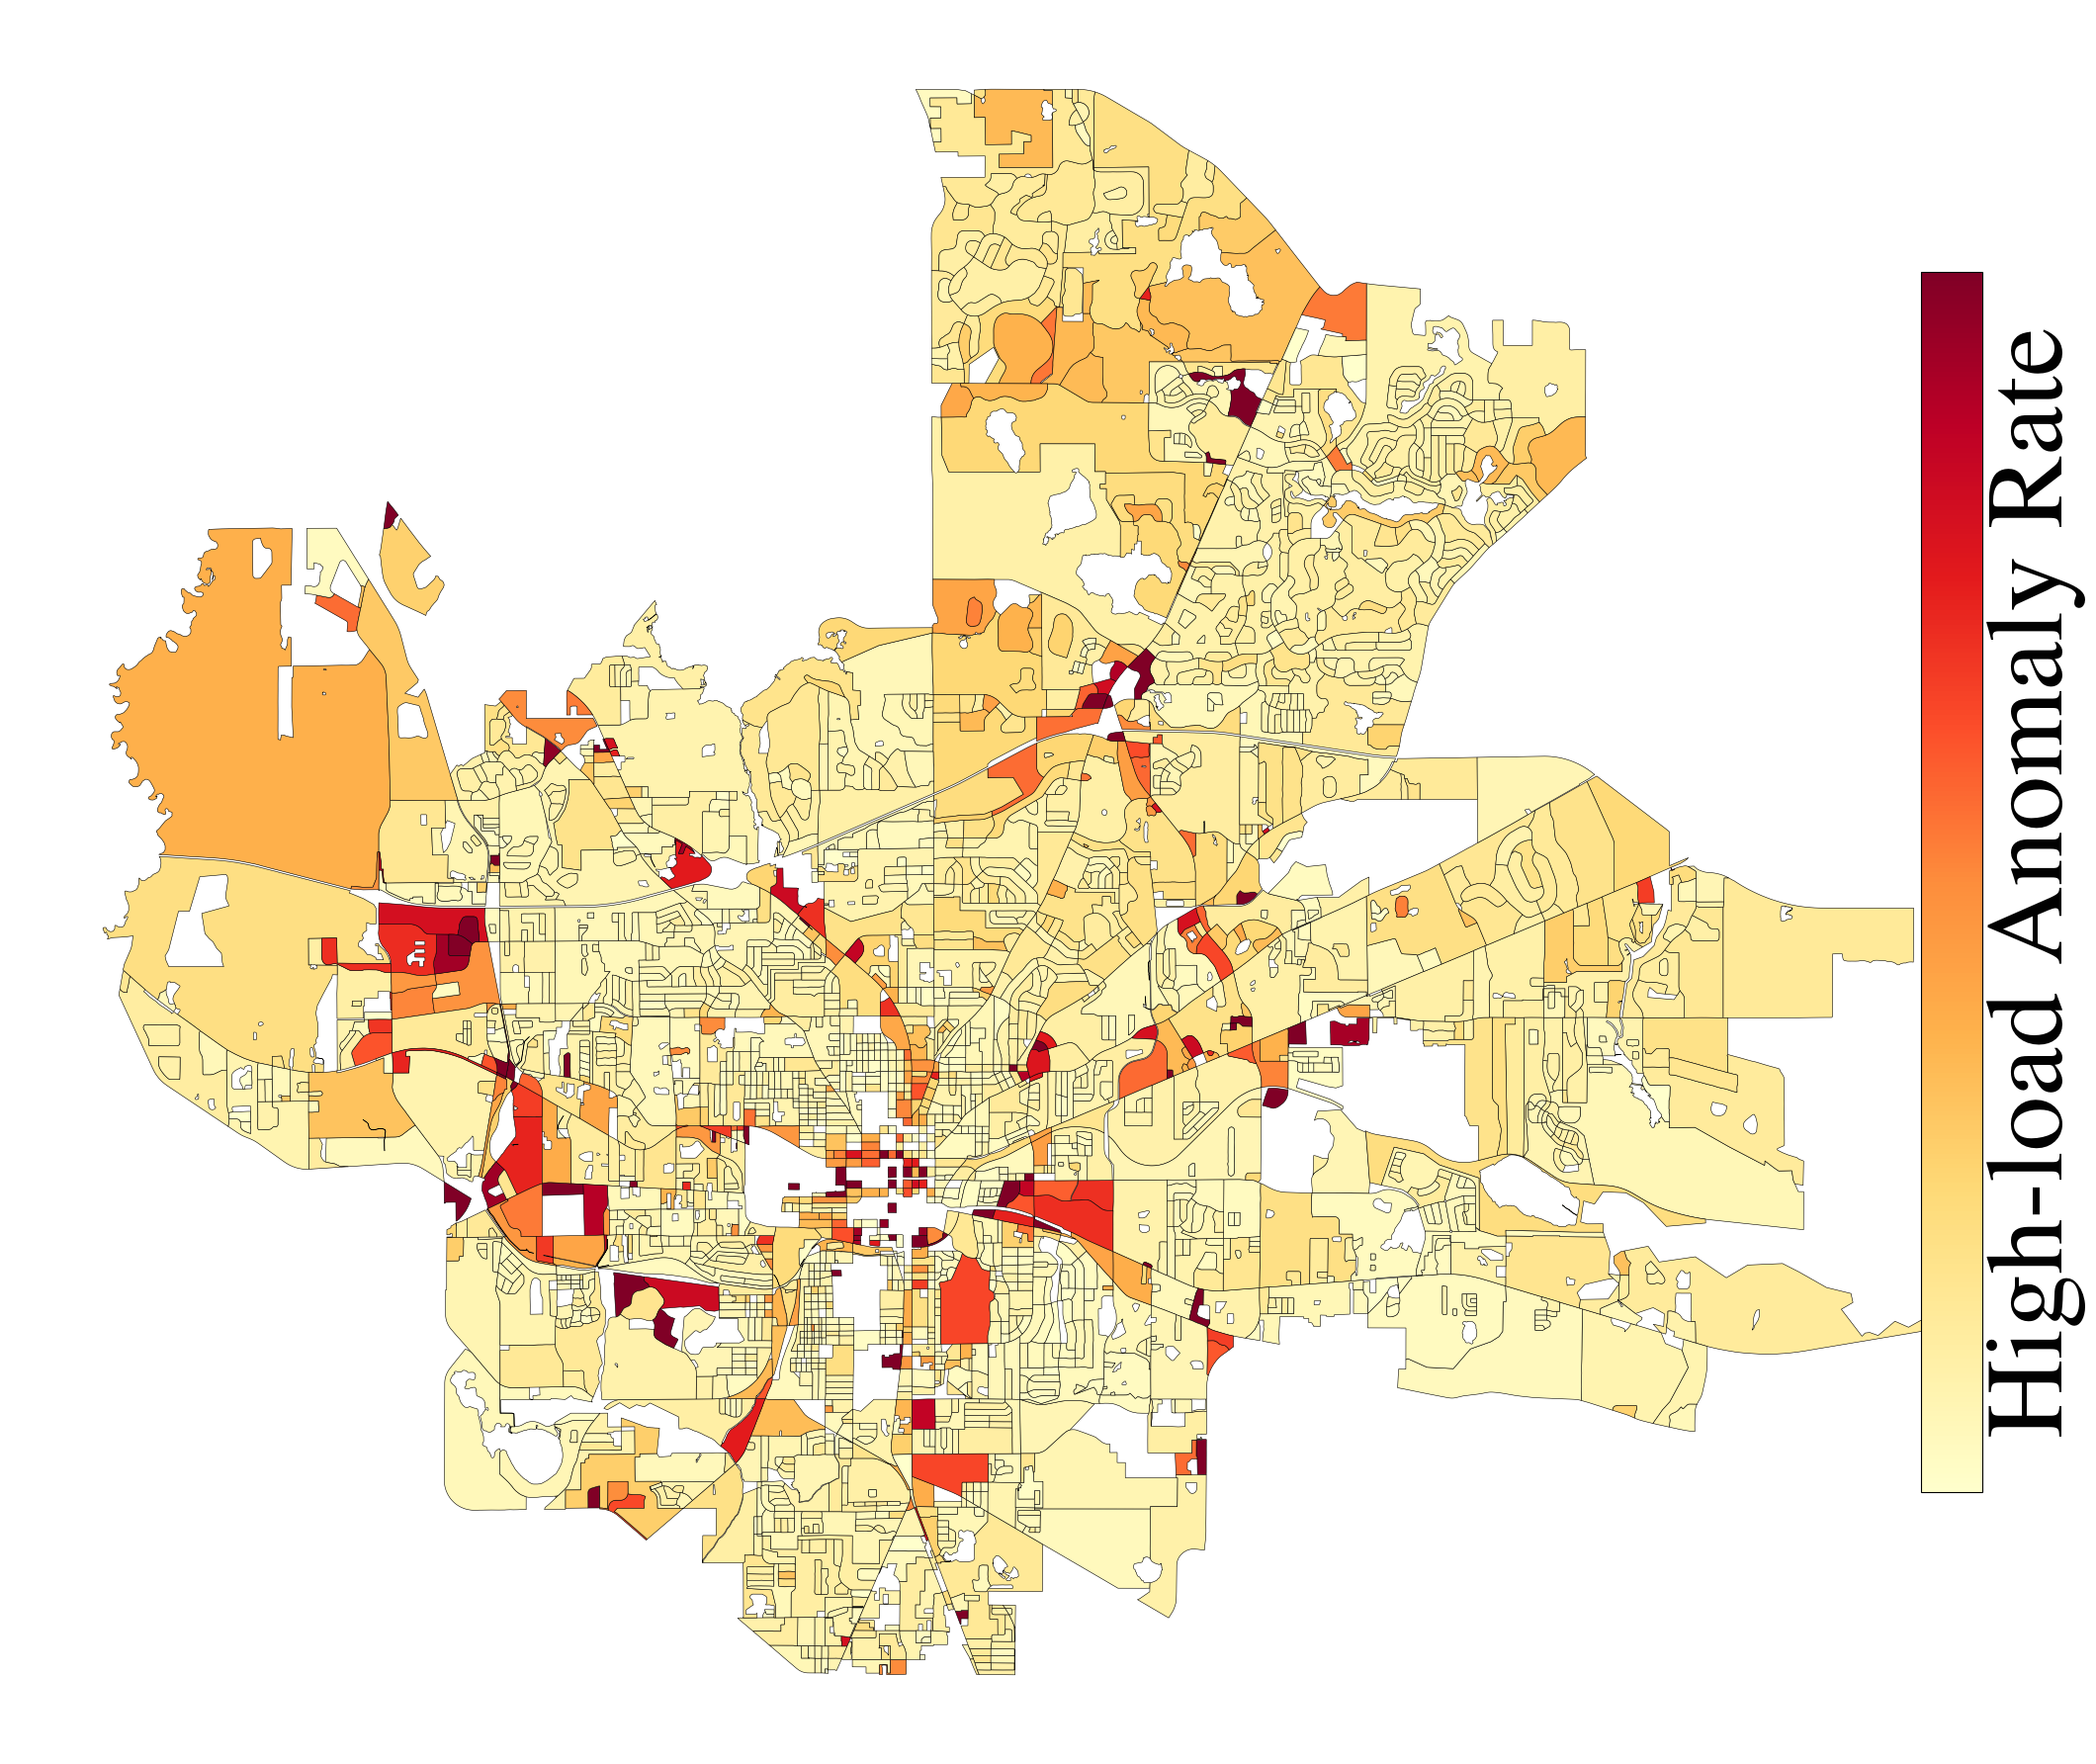

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(30, 18))

color_col = "prop_high"

geo_data.plot(
    ax=ax,
    column=color_col,
    cmap="YlOrRd",
    legend=True,
    legend_kwds={
        "label": "High-load Anomalies Rate",
        "orientation": "vertical",
        "shrink": 0.7,
        "pad": -0.05,   # legend 和地图之间的距离
    },
    edgecolor="black",
    linewidth=0.4,
    missing_kwds={"color": "lightgrey", "label": "No data"},
)

# 获取 colorbar axis
cax = fig.axes[-1]

# 调整 colorbar 刻度字体大小
#cax.tick_params(labelsize=40)
cax.set_yticks([])
cax.set_yticklabels([])

# 调整 colorbar label 字体大小
cax.set_ylabel("High-load Anomaly Rate", fontsize=80)

# 关闭坐标轴
ax.set_axis_off()

# 手动缩小 figure 内部空白
plt.subplots_adjust(
    left=0.01,
    right=0.93,
    top=0.99,
    bottom=0.01,
)

# 保存论文图，自动裁剪外部空白
fig.savefig(
    "../../../Analysis/Plot/Motivation/high_load_anomaly_map.png",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()